# Citizen Assist AI — Modelagem Linear para Aprendizado de Máquina

**2º Global Solution 2026 | FIAP**  
**Tema:** perfil dos usuários de serviços públicos digitais no Brasil.

## Objetivo
Analisar dados reais da pesquisa **TIC Domicílios 2024 – Indivíduos**, do Cetic.br/NIC.br, para identificar padrões no uso de dois serviços públicos digitais (saúde pública e documentos pessoais), construir modelos de classificação e regressão e propor melhorias para uma solução Citizen Assist AI.


### Delimitação metodológica
O módulo G (Governo eletrônico) é aplicado a pessoas com **16 anos ou mais** que utilizaram a Internet nos últimos três meses. Por isso, as análises dos serviços G1 não representam automaticamente toda a população brasileira: representam os respondentes elegíveis com respostas válidas aos itens analisados. A pesquisa pergunta se a pessoa usou a Internet para procurar informações ou realizar serviços; portanto, o indicador não significa necessariamente que o serviço foi concluído integralmente online.

## 1. Preparação do ambiente
Vamos usar pandas e NumPy para organização, Matplotlib/Seaborn para gráficos, SciPy para testes estatísticos e scikit-learn para os modelos. O `python-docx` será usado para gerar o relatório final em Word.

In [1]:
!pip -q install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels python-docx openpyxl

import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_absolute_error,
    mean_squared_error, r2_score, roc_auc_score
)
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
PASTA_SAIDA = Path('/content/resultado_citizen_assist')
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

print('Ambiente preparado.')

Ambiente preparado.


## 2. Coleta da base pública
Fonte: [Cetic.br — Microdados TIC Domicílios 2024, Indivíduos](https://www.cetic.br/pt/arquivos/domicilios/2024/individuos/).

A pesquisa possui abrangência nacional, unidade de análise em indivíduos, amostragem probabilística e inclui o Módulo G — Governo eletrônico.

Os microdados são disponibilizados originalmente pelo Cetic.br e hospedados em um repositório público no GitHub, permitindo que o Google Colab realize o carregamento automático do arquivo CSV por meio de uma URL direta (GitHub Raw), sem necessidade de upload manual.

Após a leitura, os dados são armazenados em um DataFrame utilizando a biblioteca Pandas, servindo de base para as etapas de tratamento, exploração estatística e modelagem de aprendizado de máquina.

In [2]:
URL_BASE = (
    'https://raw.githubusercontent.com/gab-dpaula/'
    'FIAP_GS2026_02_ModelagemLinear_CitizenAssistAI/'
    'refs/heads/main/Citizen-Assist-AI/dados/'
    'tic_domicilios_2024_individuos_base_de_microdados_v1.0.csv'
)

df = pd.read_csv(
    URL_BASE,
    sep=';',
    encoding='latin-1',
    low_memory=False
)

print('Dimensões da base:', df.shape)

display(df.head())

Dimensões da base: (21170, 439)


,QUEST,ID_DOMICILIO,ID_MORADOR,SEXO,IDADE,FAIXA_ETARIA,GRAU_INSTRUCAO_1,ESTUD,APOSENT,PEA,...,G1_AGREG,C8_NAO,I1A_NENHUM,J5_FAIXAS,J2_NENHUM,J3_AGREG,J3AB,C5_COB_AGREG,C5_COB_NENHUM,C6_COB_NENHUM
0,200809622,1,3,2,83,6,1,0,1,5,...,0,1,1,1,99,1,2,0,1,1
1,200809621,2,1,1,63,6,1,0,1,1,...,0,1,1,0,1,0,4,0,1,1
2,200820881,4,1,1,70,6,10,0,1,1,...,1,1,1,1,99,1,2,0,1,1
3,200818341,6,1,1,85,6,1,0,0,5,...,0,1,1,0,1,0,4,0,1,1
4,200818340,7,1,2,54,5,15,0,0,1,...,0,1,1,1,99,1,2,0,1,1


In [3]:
# Recarrega os dados originais, sem aplicar tratamentos.
df_bruto = pd.read_csv(
    URL_BASE,
    sep=';',
    encoding='latin-1',
    low_memory=False
)

# Verifica os códigos originais das variáveis de serviços.
for col in ['G1_A', 'G1_B']:
    print(f'\nDistribuição original de {col}:')
    print(df_bruto[col].value_counts(dropna=False).sort_index())


Distribuição original de G1_A:
G1_A
0     12141
1      3482
97       23
98        9
99     5515
Name: count, dtype: int64

Distribuição original de G1_B:
G1_B
0     11554
1      4071
97       19
98       11
99     5515
Name: count, dtype: int64


### 2.1 Conferência dos nomes das variáveis
O questionário identifica os serviços do Módulo G como `G1_A` a `G1_G`. As variáveis sociodemográficas podem ter rótulos abreviados no arquivo de microdados. A célula seguinte normaliza nomes e procura os campos comuns.


In [4]:
def normalizar_nome(valor):
    texto = unicodedata.normalize('NFKD', str(valor)).encode('ascii', 'ignore').decode('ascii')
    texto = texto.upper().strip()
    texto = re.sub(r'[^A-Z0-9]+', '_', texto)
    return texto.strip('_')

df.columns = [normalizar_nome(c) for c in df.columns]
print('Colunas disponíveis na base:')
print(df.columns.tolist())

# Variáveis dos dois serviços principais e dos sete serviços do questionário.
SERVICOS = {
    'G1_A': 'Documentos pessoais',
    'G1_B': 'Saúde pública',
    'G1_C': 'Educação pública',
    'G1_D': 'Direitos do trabalhador / previdência',
    'G1_E': 'Impostos e taxas',
    'G1_F': 'Polícia e segurança',
    'G1_G': 'Transporte e serviços urbanos',
}
servicos_presentes = [c for c in SERVICOS if c in df.columns]
if not {'G1_A', 'G1_B'}.issubset(df.columns):
    raise KeyError('Não encontrei G1_A e G1_B. Confira os nomes impressos acima e ajuste o dicionário de variáveis.')

# Ajuste os apelidos abaixo somente se a busca automática não encontrar uma variável.
APELIDOS = {
    'sexo': ['SEXO', 'P_SEXO', 'R_SEXO'],
    'idade': ['IDADE', 'IDADE_EXATA', 'IDADE_ANOS', 'P_IDADE'],
    'faixa_etaria': ['FAIXA_ETARIA', 'IDADE_FAIXA', 'FAIXA_DE_IDADE'],
    'escolaridade': ['ESCOLARIDADE', 'P_ESCOLARIDADE', 'GRAU_INSTRUCAO', 'P_GRAU_INSTRUCAO', 'GRAU_DE_INSTRUCAO', 'INSTRUCAO', 'EDUCACAO'],
    'renda': ['RENDA_FAMILIAR', 'FAIXA_RENDA_FAMILIAR', 'RENDAFAM', 'FAIXA_RENDA', 'RENDA_FAM', 'P_RENDA', 'RENDA'],
    'classe': ['CLASSE', 'P_CLASSE', 'CLASSE_SOCIAL', 'CLASSE_ECONOMICA', 'CLASS'],
}

def encontrar_coluna(apelidos, colunas):
    for candidato in apelidos:
        c = normalizar_nome(candidato)
        if c in colunas:
            return c
    return None

MAPA = {nome: encontrar_coluna(lista, df.columns) for nome, lista in APELIDOS.items()}
print('Mapeamento sociodemográfico localizado:')
print(MAPA)
print('Serviços identificados:', servicos_presentes)

Colunas disponíveis na base:
['QUEST', 'ID_DOMICILIO', 'ID_MORADOR', 'SEXO', 'IDADE', 'FAIXA_ETARIA', 'GRAU_INSTRUCAO_1', 'ESTUD', 'APOSENT', 'PEA', 'OCUP_12', 'OCUP_29', 'OCUP_32', 'RENDA_PESSOAL', 'RELIGIAO', 'RACA', 'C1', 'C2_D', 'C2_E', 'C2_F', 'C2_G', 'C2_I', 'C2_J', 'C2_OUTRO', 'C2A', 'C3', 'C4', 'C5_A', 'C5_B', 'C5_C', 'C5_D', 'C5_E', 'C5_F', 'C5_OUTRO', 'C6_A', 'C6_B', 'C6_C', 'C6_D', 'C6_E', 'C6_F', 'C6_G', 'C6_OUTRO', 'C6A', 'C7_A', 'C7_B', 'C7_C', 'C7_D1', 'C7_E', 'C7_F', 'C8_A', 'C8_B', 'C8_C', 'C8_D', 'C8_E', 'C8_F', 'C8_G', 'C8_H', 'C9_A', 'C9_B', 'C9_C', 'C9_D', 'C9_F', 'C9_G', 'C9_E', 'C10_A', 'C10_B', 'C10_C', 'C10_D', 'C10_E', 'C10_F', 'C11_A', 'C11_B', 'C11_C', 'H2', 'H3_A1', 'H3_B1', 'H3_C1', 'H3_D1', 'H3_E1', 'H3_F1', 'H3_G1', 'H3_H1', 'H3_I1', 'H3_OUTRO1', 'H5_A', 'H5_B', 'H5_C', 'H5_D', 'H5_F', 'H5_G', 'H5_I', 'H5_J', 'H5_K', 'H5_L', 'H5_N', 'H5_O', 'H5_P', 'H5_OUTRO', 'H6', 'H8_A', 'H8_B', 'H8_C', 'H8_D', 'H8_E', 'H8_F', 'H8_G', 'H8_H', 'H9_A', 'H9_B', 'H9_C', '

## 3. Limpeza e preparação dos dados
Nas variáveis do Módulo G, o código 1 representa a utilização do serviço e o código 0 representa a não utilização. Os demais códigos, como 97, 98 e 99, são tratados como valores ausentes, conforme a codificação identificada nos microdados.

A amostra analítica será formada por respondentes com respostas válidas (0 ou 1) nos dois serviços principais: documentos pessoais e saúde pública.

O índice de habilidades digitais será calculado a partir dos itens I1A_A a I1A_L, quando disponíveis, considerando a proporção de respostas positivas entre os itens válidos. Esse índice é uma variável explicativa auxiliar, não uma escala oficial do Cetic.br.

In [5]:
# Converte as respostas dos serviços para números.
# Preserva 0 (não utilizou) e 1 (utilizou).
for col in servicos_presentes:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df.loc[~df[col].isin([0, 1]), col] = np.nan

# Cria a amostra com respostas válidas para os dois serviços principais.
base = df[df[['G1_A', 'G1_B']].notna().all(axis=1)].copy()

# Cria as variáveis-alvo.
base['uso_documentos'] = (base['G1_A'] == 1).astype(int)
base['uso_saude'] = (base['G1_B'] == 1).astype(int)

# Índice de habilidades digitais.
itens_habilidades = [
    f'I1A_{letra}'
    for letra in list('ABCDEFGHIJKL')
    if f'I1A_{letra}' in df.columns
]

if len(itens_habilidades) >= 4:
    for col in itens_habilidades:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df.loc[~df[col].isin([0, 1]), col] = np.nan

    base = df.loc[base.index].copy()

    respostas_hab = base[itens_habilidades]
    base['indice_habilidades_digitais'] = respostas_hab.mean(axis=1)
else:
    base['indice_habilidades_digitais'] = np.nan

# Recria os alvos após o recorte.
base['uso_documentos'] = (base['G1_A'] == 1).astype(int)
base['uso_saude'] = (base['G1_B'] == 1).astype(int)

# Apresenta o resumo da amostra.
print(f'Registros brutos: {len(df):,}')
print(f'Registros válidos para os dois serviços: {len(base):,}')
print(f'Itens de habilidades digitais encontrados: {len(itens_habilidades)}')

print(
    'Proporção de respostas válidas nos dois serviços:',
    round(len(base) / len(df) * 100, 2),
    '%'
)

print('\nDistribuição de uso de documentos:')
print(base['uso_documentos'].value_counts())

print('\nDistribuição de uso de saúde:')
print(base['uso_saude'].value_counts())

Registros brutos: 21,170
Registros válidos para os dois serviços: 15,602
Itens de habilidades digitais encontrados: 12
Proporção de respostas válidas nos dois serviços: 73.7 %

Distribuição de uso de documentos:
uso_documentos
0    12122
1     3480
Name: count, dtype: int64

Distribuição de uso de saúde:
uso_saude
0    11533
1     4069
Name: count, dtype: int64


In [6]:
# Comparação entre a base original e a base utilizada na análise.

print('Dimensões da base original:', df.shape)
print('Dimensões da base analítica:', base.shape)

servicos = ['G1_A', 'G1_B', 'G1_C', 'G1_D',
            'G1_E', 'G1_F', 'G1_G']

print('\nDistribuição na base original:')
display(df[servicos].apply(
    lambda coluna: coluna.value_counts(dropna=False)
))

print('\nDistribuição na base analítica:')
display(base[servicos].apply(
    lambda coluna: coluna.value_counts(dropna=False)
))

Dimensões da base original: (21170, 439)
Dimensões da base analítica: (15602, 442)

Distribuição na base original:


,G1_A,G1_B,G1_C,G1_D,G1_E,G1_F,G1_G
0.0,12141,11554,13190,12287,12682,14386,14313
NaN,5547,5545,5535,5539,5535,5544,5544
1.0,3482,4071,2445,3344,2953,1240,1313



Distribuição na base analítica:


,G1_A,G1_B,G1_C,G1_D,G1_E,G1_F,G1_G
0.0,12122.0,11533.0,13148,12247,12642,14347,14271
1.0,3480.0,4069.0,2444,3341,2950,1237,1313
NaN,NaN,NaN,10,14,10,18,18


### 3.1 Construção das variáveis explicativas
Idade exata é tratada como numérica; faixa etária, sexo, escolaridade, renda e classe são tratados como categorias. A regressão não interpreta códigos categóricos como se fossem distâncias numéricas: as categorias passam por codificação *one-hot*.

In [7]:
features = pd.DataFrame(index=base.index)
colunas_numericas = []
colunas_categoricas = []

if MAPA['idade']:
    features['idade'] = pd.to_numeric(base[MAPA['idade']], errors='coerce')
    colunas_numericas.append('idade')
elif MAPA['faixa_etaria']:
    features['faixa_etaria'] = base[MAPA['faixa_etaria']].astype('string')
    colunas_categoricas.append('faixa_etaria')

for variavel in ['sexo', 'escolaridade', 'renda', 'classe']:
    coluna = MAPA[variavel]
    if coluna:
        nome = variavel
        features[nome] = base[coluna].astype('string').replace({'nan': pd.NA, 'None': pd.NA})
        colunas_categoricas.append(nome)

if base['indice_habilidades_digitais'].notna().sum() > 0:
    features['indice_habilidades_digitais'] = base['indice_habilidades_digitais']
    colunas_numericas.append('indice_habilidades_digitais')

# Remove atributos sem informação ou com valor único.
remover = [c for c in features.columns if features[c].notna().sum() == 0 or features[c].nunique(dropna=True) <= 1]
features = features.drop(columns=remover)
colunas_numericas = [c for c in colunas_numericas if c in features.columns]
colunas_categoricas = [c for c in colunas_categoricas if c in features.columns]

if features.shape[1] == 0:
    raise ValueError('Nenhuma variável explicativa foi identificada. Revise o mapeamento sociodemográfico.')

print('Variáveis explicativas:', features.columns.tolist())
print('Numéricas:', colunas_numericas)
print('Categóricas:', colunas_categoricas)
display(features.head())

Variáveis explicativas: ['idade', 'sexo', 'renda', 'indice_habilidades_digitais']
Numéricas: ['idade', 'indice_habilidades_digitais']
Categóricas: ['sexo', 'renda']


,idade,sexo,renda,indice_habilidades_digitais
0,83,2,1,0.00
2,70,1,2,0.00
4,54,2,1,0.00
5,28,2,1,0.75
6,55,1,1,0.00


## 4. Análise exploratória e estatística descritiva
Observação do perfil da amostra, frequência de uso dos serviços, valores ausentes e distribuição das variáveis explicativas.

In [8]:
# Tabela de prevalência dos serviços.
# Código 1 = utilizou | Código 0 = não utilizou.

linhas_servicos = []

for col, rotulo in SERVICOS.items():
    if col in base.columns:
        validos = base[col].dropna()

        linhas_servicos.append({
            'Variável': col,
            'Serviço': rotulo,
            'Respostas válidas': int(len(validos)),
            'Usaram (n)': int((validos == 1).sum()),
            'Não usaram (n)': int((validos == 0).sum()),
            'Uso (%)': float((validos == 1).mean() * 100)
            if len(validos) else np.nan,
        })

prevalencia = pd.DataFrame(linhas_servicos)
prevalencia = prevalencia.sort_values('Uso (%)', ascending=False)

display(prevalencia.round(2))

prevalencia.to_csv(
    PASTA_SAIDA / 'prevalencia_servicos.csv',
    index=False,
    encoding='utf-8-sig'
)

,Variável,Serviço,Respostas válidas,Usaram (n),Não usaram (n),Uso (%)
1,G1_B,Saúde pública,15602,4069,11533,26.08
0,G1_A,Documentos pessoais,15602,3480,12122,22.30
3,G1_D,Direitos do trabalhador / previdência,15588,3341,12247,21.43
4,G1_E,Impostos e taxas,15592,2950,12642,18.92
2,G1_C,Educação pública,15592,2444,13148,15.67
6,G1_G,Transporte e serviços urbanos,15584,1313,14271,8.43
5,G1_F,Polícia e segurança,15584,1237,14347,7.94


In [9]:
# Conferência dos códigos das respostas dos serviços.
for col, rotulo in SERVICOS.items():
    if col in base.columns:
        print(f'\n{rotulo} ({col})')
        print(base[col].value_counts(dropna=False).sort_index())


Documentos pessoais (G1_A)
G1_A
0.0    12122
1.0     3480
Name: count, dtype: int64

Saúde pública (G1_B)
G1_B
0.0    11533
1.0     4069
Name: count, dtype: int64

Educação pública (G1_C)
G1_C
0.0    13148
1.0     2444
NaN       10
Name: count, dtype: int64

Direitos do trabalhador / previdência (G1_D)
G1_D
0.0    12247
1.0     3341
NaN       14
Name: count, dtype: int64

Impostos e taxas (G1_E)
G1_E
0.0    12642
1.0     2950
NaN       10
Name: count, dtype: int64

Polícia e segurança (G1_F)
G1_F
0.0    14347
1.0     1237
NaN       18
Name: count, dtype: int64

Transporte e serviços urbanos (G1_G)
G1_G
0.0    14271
1.0     1313
NaN       18
Name: count, dtype: int64


### 4.1 Visualização da frequência dos serviços

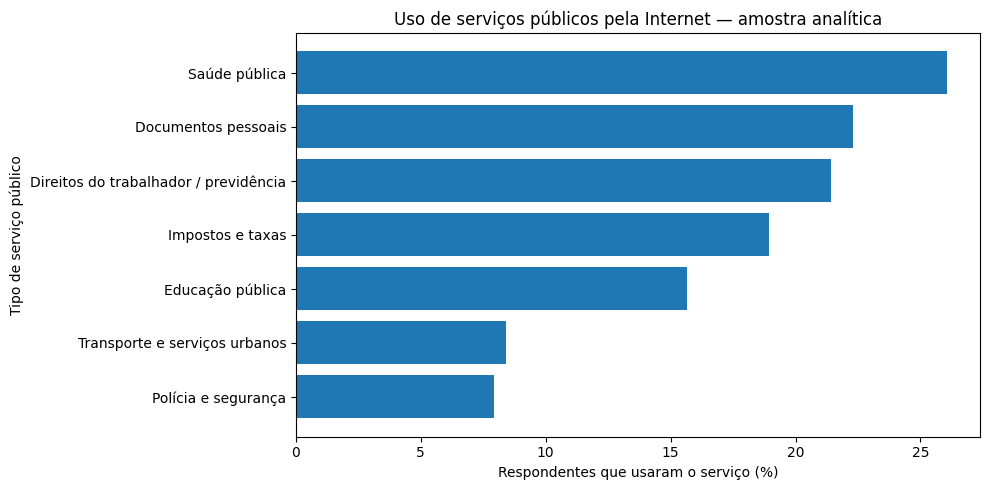

In [10]:
plt.figure(figsize=(10, 5))
ordem = prevalencia.sort_values('Uso (%)', ascending=True)
plt.barh(ordem['Serviço'], ordem['Uso (%)'])
plt.xlabel('Respondentes que usaram o serviço (%)')
plt.ylabel('Tipo de serviço público')
plt.title('Uso de serviços públicos pela Internet — amostra analítica')
plt.tight_layout()
plt.savefig(PASTA_SAIDA / 'uso_servicos.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Probabilidades e análise bivariada
Serão calculadas probabilidades condicionais empíricas, por exemplo: proporção de uso de saúde pública entre respondentes de cada categoria de escolaridade. Em seguida, serão avaliadas associações entre o uso do serviço e as variáveis categóricas pelo teste qui-quadrado de independência. Para a idade numérica, será usado o teste de Mann–Whitney entre grupos de uso e não uso.

**Hipóteses do qui-quadrado:**  
H₀: a variável sociodemográfica e o uso do serviço são independentes.  
H₁: existe associação entre a variável sociodemográfica e o uso do serviço.

In [11]:
def qui_quadrado_categorico(dados, variavel, alvo, nome_alvo):
    tabela = pd.crosstab(dados[variavel], dados[alvo])
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        return None
    chi2, p, gl, esperados = chi2_contingency(tabela)
    n = tabela.to_numpy().sum()
    minimo = min(tabela.shape)
    cramers_v = np.sqrt(chi2 / (n * (minimo - 1))) if minimo > 1 and n > 0 else np.nan
    return {
        'Variável': variavel, 'Serviço': nome_alvo, 'Qui-quadrado': chi2,
        'Graus de liberdade': gl, 'p-valor': p, 'V de Cramer': cramers_v,
        'Menor frequência esperada': float(np.min(esperados))
    }

resultados_testes = []
for variavel in colunas_categoricas:
    for alvo, nome in [('uso_saude', 'Saúde pública'), ('uso_documentos', 'Documentos pessoais')]:
        res = qui_quadrado_categorico(base.join(features[[variavel]]), variavel, alvo, nome)
        if res:
            resultados_testes.append(res)

testes_df = pd.DataFrame(resultados_testes)
if not testes_df.empty:
    testes_df['Conclusão (5%)'] = np.where(testes_df['p-valor'] < 0.05, 'Rejeita H0; associação estatística', 'Não rejeita H0')
    display(testes_df.round(4))
    testes_df.to_csv(PASTA_SAIDA / 'testes_hipotese.csv', index=False, encoding='utf-8-sig')
else:
    print('Não foi possível realizar o qui-quadrado com as variáveis categóricas disponíveis.')

# Probabilidade condicional por escolaridade ou sexo, conforme disponibilidade.
variavel_grupo = 'escolaridade' if 'escolaridade' in features.columns else (colunas_categoricas[0] if colunas_categoricas else None)
if variavel_grupo:
    probabilidade = base.join(features[[variavel_grupo]]).groupby(variavel_grupo, dropna=False).agg(
        P_uso_saude=('uso_saude', 'mean'),
        P_uso_documentos=('uso_documentos', 'mean'),
        N=('uso_saude', 'size')
    ).reset_index()
    probabilidade['P_uso_saude_%'] = probabilidade['P_uso_saude'] * 100
    probabilidade['P_uso_documentos_%'] = probabilidade['P_uso_documentos'] * 100
    display(probabilidade.round(3))
    probabilidade.to_csv(PASTA_SAIDA / 'probabilidades_condicionais.csv', index=False, encoding='utf-8-sig')

# Comparação de idade entre usuários e não usuários, se idade exata estiver disponível.
if 'idade' in features.columns:
    idade_df = base[['uso_saude', 'uso_documentos']].join(features[['idade']]).dropna(subset=['idade'])
    for alvo, nome in [('uso_saude', 'Saúde pública'), ('uso_documentos', 'Documentos pessoais')]:
        g1 = idade_df.loc[idade_df[alvo] == 1, 'idade']
        g0 = idade_df.loc[idade_df[alvo] == 0, 'idade']
        if len(g1) >= 5 and len(g0) >= 5:
            u, p = mannwhitneyu(g1, g0, alternative='two-sided')
            print(f'Mann–Whitney — {nome}: mediana usuários={g1.median():.1f}; não usuários={g0.median():.1f}; p={p:.5f}')

,Variável,Serviço,Qui-quadrado,Graus de liberdade,p-valor,V de Cramer,Menor frequência esperada,Conclusão (5%)
0,sexo,Saúde pública,97.3050,1,0.0,0.0790,1744.2297,Rejeita H0; associação estatística
1,sexo,Documentos pessoais,91.2043,1,0.0,0.0765,1491.7472,Rejeita H0; associação estatística
2,renda,Saúde pública,127.4813,10,0.0,0.0904,4.1728,Rejeita H0; associação estatística
3,renda,Documentos pessoais,335.9358,10,0.0,0.1467,3.5688,Rejeita H0; associação estatística


,sexo,P_uso_saude,P_uso_documentos,N,P_uso_saude_%,P_uso_documentos_%
0,1,0.221,0.260,6688,22.069,25.987
1,2,0.291,0.195,8914,29.089,19.542


Mann–Whitney — Saúde pública: mediana usuários=38.0; não usuários=42.0; p=0.00000
Mann–Whitney — Documentos pessoais: mediana usuários=31.0; não usuários=45.0; p=0.00000


## 6. Análise multivariada — regressão logística
Foram desenvolvidos dois modelos de regressão logística binária para identificar padrões associados à utilização de serviços públicos pela Internet.

Modelo 1 — Saúde pública: classificação da utilização de serviços digitais de saúde pública (G1_B).

Modelo 2 — Documentos pessoais: classificação da utilização de serviços digitais relacionados a documentos pessoais (G1_A).

As variáveis explicativas incluem atributos sociodemográficos disponíveis na base e o índice de habilidades digitais, quando disponível.

A amostra foi dividida em conjuntos de treinamento (80%) e teste (20%). O desempenho dos modelos foi avaliado por meio de acurácia, precisão, revocação, F1-score, matriz de confusão e área sob a curva ROC (AUC).

Os resultados são apresentados por meio das métricas de classificação e das matrizes de confusão geradas durante a execução. A interpretação comparativa e a discussão das limitações dos modelos são desenvolvidas no relatório.

In [12]:
def montar_preprocessador(numericas, categoricas):
    transformadores = []
    if numericas:
        pipeline_num = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ])
        transformadores.append(('num', pipeline_num, numericas))
    if categoricas:
        pipeline_cat = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ])
        transformadores.append(('cat', pipeline_cat, categoricas))
    return ColumnTransformer(transformadores, remainder='drop')

resultados_logisticos = {}
metricas_classificacao = []
matrizes_confusao = {}

for alvo, nome in [('uso_saude', 'Saúde pública'), ('uso_documentos', 'Documentos pessoais')]:
    dados_modelo = features.join(base[[alvo]])
    X = dados_modelo[features.columns]
    y = dados_modelo[alvo].astype(int)
    if y.nunique() < 2 or y.value_counts().min() < 5 or len(X) < 50:
        print(f'Modelo de {nome} não ajustado: amostra/classe insuficiente.')
        continue

    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )
    pipeline = Pipeline([
        ('preprocessamento', montar_preprocessador(colunas_numericas, colunas_categoricas)),
        ('modelo', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))
    ])
    pipeline.fit(X_treino, y_treino)
    pred = pipeline.predict(X_teste)
    proba = pipeline.predict_proba(X_teste)[:, 1]

    m = {
        'Serviço': nome,
        'N teste': len(y_teste),
        'Acurácia': accuracy_score(y_teste, pred),
        'Precisão': precision_score(y_teste, pred, zero_division=0),
        'Revocação': recall_score(y_teste, pred, zero_division=0),
        'F1': f1_score(y_teste, pred, zero_division=0),
        'AUC': roc_auc_score(y_teste, proba) if y_teste.nunique() == 2 else np.nan,
    }
    metricas_classificacao.append(m)
    matrizes_confusao[nome] = confusion_matrix(y_teste, pred, labels=[0, 1])
    resultados_logisticos[nome] = pipeline
    print(f'\nRelatório de classificação — {nome}')
    print(classification_report(y_teste, pred, zero_division=0))
    print('Matriz de confusão [ [TN, FP], [FN, TP] ]:')
    print(matrizes_confusao[nome])

metricas_logit_df = pd.DataFrame(metricas_classificacao)
if not metricas_logit_df.empty:
    display(metricas_logit_df.round(4))
    metricas_logit_df.to_csv(PASTA_SAIDA / 'metricas_regressao_logistica.csv', index=False, encoding='utf-8-sig')


Relatório de classificação — Saúde pública
              precision    recall  f1-score   support

           0       0.82      0.71      0.76      2307
           1       0.41      0.57      0.48       814

    accuracy                           0.68      3121
   macro avg       0.62      0.64      0.62      3121
weighted avg       0.72      0.68      0.69      3121

Matriz de confusão [ [TN, FP], [FN, TP] ]:
[[1645  662]
 [ 351  463]]

Relatório de classificação — Documentos pessoais
              precision    recall  f1-score   support

           0       0.90      0.78      0.84      2425
           1       0.48      0.69      0.56       696

    accuracy                           0.76      3121
   macro avg       0.69      0.74      0.70      3121
weighted avg       0.80      0.76      0.78      3121

Matriz de confusão [ [TN, FP], [FN, TP] ]:
[[1894  531]
 [ 214  482]]


,Serviço,N teste,Acurácia,Precisão,Revocação,F1,AUC
0,Saúde pública,3121,0.6754,0.4116,0.5688,0.4776,0.6933
1,Documentos pessoais,3121,0.7613,0.4758,0.6925,0.5641,0.8132


### 6.1 Matrizes de confusão
Na matriz, a primeira linha representa os casos reais sem uso do serviço (TN e FP); a segunda representa os casos reais com uso (FN e TP). Falsos negativos merecem atenção em um assistente público, pois representam cidadãos cujo uso do serviço não foi identificado pelo modelo.

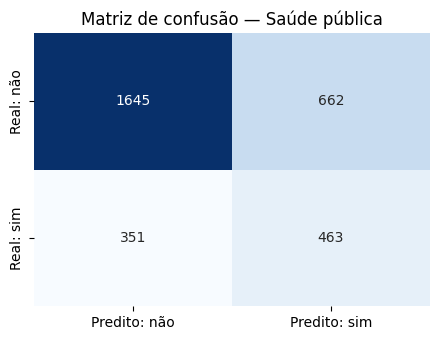

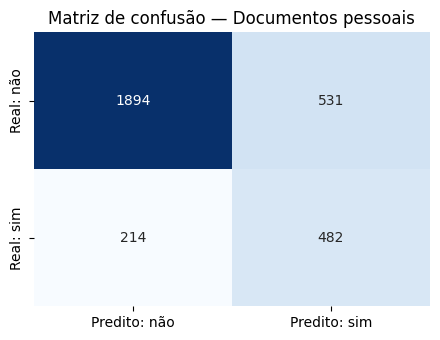

In [13]:
for nome, matriz in matrizes_confusao.items():
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predito: não', 'Predito: sim'],
                yticklabels=['Real: não', 'Real: sim'])
    plt.title(f'Matriz de confusão — {nome}')
    plt.tight_layout()
    nome_arquivo = 'matriz_' + normalizar_nome(nome).lower() + '.png'
    plt.savefig(PASTA_SAIDA / nome_arquivo, dpi=180, bbox_inches='tight')
    plt.show()

## 7. Modelagem linear — regressão linear múltipla
Para integrar os diferentes tipos de atendimento em um indicador único, será calculada a **quantidade de tipos de serviço público** utilizados por cada respondente, de 0 a 7. A regressão linear tentará estimar esse total com as variáveis sociodemográficas e o índice de habilidades digitais disponíveis.

Como o alvo é uma contagem limitada entre 0 e 7, o modelo linear é usado aqui como exercício didático de modelagem linear, conforme a disciplina; não é o único modelo estatístico possível para esse tipo de variável. Serão avaliados R², MAE e RMSE.

,N teste,R²,MAE,RMSE,Média real,Média prevista
0,3109,0.3601,0.9535,1.2764,1.1962,1.2138


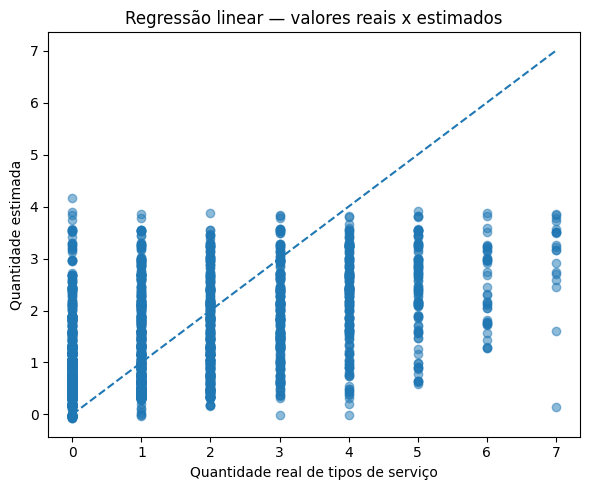

In [14]:
colunas_g1_completas = [c for c in SERVICOS if c in base.columns]
base_linear = base[base[colunas_g1_completas].notna().all(axis=1)].copy()
base_linear['quantidade_tipos_servico'] = (base_linear[colunas_g1_completas] == 1).sum(axis=1)
X_linear = features.loc[base_linear.index]
y_linear = base_linear['quantidade_tipos_servico'].astype(float)

metricas_linear = None
modelo_linear = None
if len(base_linear) >= 50 and y_linear.nunique() > 1:
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X_linear, y_linear, test_size=0.20, random_state=RANDOM_STATE
    )
    modelo_linear = Pipeline([
        ('preprocessamento', montar_preprocessador(colunas_numericas, colunas_categoricas)),
        ('modelo', LinearRegression())
    ])
    modelo_linear.fit(X_treino, y_treino)
    pred_linear = modelo_linear.predict(X_teste)
    metricas_linear = {
        'N teste': len(y_teste),
        'R²': r2_score(y_teste, pred_linear),
        'MAE': mean_absolute_error(y_teste, pred_linear),
        'RMSE': mean_squared_error(y_teste, pred_linear) ** 0.5,
        'Média real': y_teste.mean(),
        'Média prevista': pred_linear.mean(),
    }
    display(pd.DataFrame([metricas_linear]).round(4))
    pd.DataFrame([metricas_linear]).to_csv(PASTA_SAIDA / 'metricas_regressao_linear.csv', index=False, encoding='utf-8-sig')
    plt.figure(figsize=(6, 5))
    plt.scatter(y_teste, pred_linear, alpha=0.5)
    plt.plot([0, 7], [0, 7], linestyle='--')
    plt.xlabel('Quantidade real de tipos de serviço')
    plt.ylabel('Quantidade estimada')
    plt.title('Regressão linear — valores reais x estimados')
    plt.tight_layout()
    plt.savefig(PASTA_SAIDA / 'regressao_linear_real_vs_previsto.png', dpi=180, bbox_inches='tight')
    plt.show()
else:
    print('Regressão linear não ajustada: quantidade insuficiente de registros completos ou variação no alvo.')

# 8. Interpretação dos resultados e aplicações Citizen Assist AI

## 8.1 Comparação da utilização dos serviços públicos

Entre os dois serviços analisados, a saúde pública apresentou a maior proporção de utilização na amostra, com 26,08%, enquanto os serviços relacionados a documentos pessoais apresentaram 22,30%.

A diferença indica que, entre os respondentes com respostas válidas, os serviços digitais de saúde foram mais utilizados do que os serviços digitais relacionados a documentos pessoais.

Considerando os demais serviços analisados, direitos do trabalhador e previdência apresentaram 21,43% de utilização, impostos e taxas 18,92%, educação pública 15,67%, transporte e serviços urbanos 8,43% e polícia e segurança 7,94%.

Esses percentuais descrevem a amostra analisada e não devem ser interpretados como estimativas oficiais nacionais ponderadas.

## 8.2 Variação das proporções entre grupos sociodemográficos

As probabilidades condicionais e os testes bivariados indicaram diferenças na utilização dos serviços conforme sexo e renda.

Na comparação por sexo, a categoria identificada pelo código 1 apresentou utilização de saúde pública de 22,07% e de documentos pessoais de 25,99%. Na categoria identificada pelo código 2, os percentuais foram de 29,09% para saúde pública e 19,54% para documentos pessoais.

Na análise de renda, os testes qui-quadrado também identificaram associações estatisticamente significativas com a utilização dos dois serviços.

Não foram apresentados resultados de testes específicos para escolaridade e classe econômica, pois essas variáveis não foram identificadas entre os atributos efetivamente utilizados nesta execução.

## 8.3 Associações estatisticamente significativas

Os testes qui-quadrado identificaram associações estatisticamente significativas entre sexo e utilização dos serviços, assim como entre renda e utilização dos serviços, considerando o nível de significância de 5%.

Os resultados foram:

Sexo e saúde pública: V de Cramer = 0,0790.

Sexo e documentos pessoais: V de Cramer = 0,0765.

Renda e saúde pública: V de Cramer = 0,0904.

Renda e documentos pessoais: V de Cramer = 0,1467.

Embora todas as associações tenham apresentado significância estatística, os valores do V de Cramer indicam intensidades relativamente baixas. A associação mais expressiva ocorreu entre renda e utilização de documentos pessoais.

O teste de Mann–Whitney também identificou diferenças estatisticamente significativas na idade dos usuários e não usuários. Para saúde pública, as medianas foram de 38 e 42 anos, respectivamente. Para documentos pessoais, foram de 31 e 45 anos.

É importante observar que os testes de renda apresentaram frequências esperadas mínimas inferiores a 5 (4,17 e 3,57), o que exige cautela na interpretação dos resultados do qui-quadrado.

## 8.4 Desempenho dos modelos de regressão logística

Os dois modelos apresentaram resultados diferentes.

O modelo de saúde pública obteve acurácia de 67,54%, precisão de 41,16%, revocação de 56,88%, F1-score de 47,76% e AUC de 0,6933.

O modelo de documentos pessoais apresentou acurácia de 76,13%, precisão de 47,58%, revocação de 69,25%, F1-score de 56,41% e AUC de 0,8132.

Na comparação, o modelo de documentos pessoais apresentou melhor desempenho, especialmente em revocação e AUC. Isso indica maior capacidade de identificar os usuários reais desse serviço e de diferenciar usuários de não usuários.

Entretanto, ambos os modelos apresentaram limitações de precisão, demonstrando que parte dos indivíduos classificados como usuários não utilizou efetivamente os serviços.

## 8.5 Desempenho da regressão linear

A regressão linear múltipla foi utilizada para estimar a quantidade de tipos de serviços públicos utilizados pelos respondentes, considerando os sete serviços do Módulo G.

O modelo apresentou R² de 0,3601, indicando que aproximadamente 36,01% da variação na quantidade de serviços utilizados foi explicada pelas variáveis explicativas na amostra de teste.

O erro absoluto médio (MAE) foi de 0,9535, indicando uma diferença média próxima de um tipo de serviço entre os valores reais e estimados.

O RMSE foi de 1,2764, indicando que erros maiores também influenciaram o desempenho do modelo.

Dessa forma, a regressão linear conseguiu explicar parte da variação na quantidade de serviços utilizados, mas ainda apresenta limitações para estimativas individuais mais precisas.

## 8.6 Aplicações dos resultados no Citizen Assist AI

Os resultados demonstram a importância de desenvolver uma solução digital acessível, capaz de atender cidadãos com diferentes características e níveis de familiaridade com a tecnologia.

Com base nas barreiras e nos padrões observados, o Citizen Assist AI pode incorporar as seguintes funcionalidades:

Linguagem simples: apresentar informações públicas com textos objetivos e acessíveis, facilitando a compreensão dos procedimentos.

Atendimento por texto e voz: oferecer diferentes formas de interação, considerando usuários com diferentes níveis de habilidade digital.

Orientação passo a passo: explicar documentos necessários, etapas de solicitação, prazos e procedimentos para acessar serviços públicos.

Roteamento para órgãos públicos: direcionar o cidadão ao órgão responsável pelo serviço solicitado, reduzindo dificuldades na localização das informações.

Encaminhamento humano: permitir que o usuário seja direcionado a um atendimento especializado quando a inteligência artificial não conseguir resolver sua necessidade.

A solução também pode priorizar fluxos de orientação para serviços de saúde e documentos pessoais, que apresentaram as maiores proporções de utilização entre os serviços analisados.

Dessa maneira, o Citizen Assist AI busca reduzir barreiras de acesso à informação, facilitar a navegação pelos serviços públicos digitais e oferecer suporte mais inclusivo aos cidadãos.

## Consideração final:
os resultados apresentados identificam associações e padrões de utilização, mas não demonstram relações de causalidade. Além disso, as métricas dos modelos devem ser interpretadas considerando as limitações das variáveis disponíveis, o desequilíbrio entre as classes e as características da amostra.